## 1. Importe und Konfiguration

In [1]:
import os
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import sys
!{sys.executable} -m pip install wandb -q

from pathlib import Path
from collections import Counter
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset


## 2. Pfad des Datensatzes und Prüfung der Verzeichnisstruktur

In [6]:
DATASET_PATH = './dataset'
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Das Verzeichnis {DATASET_PATH} existiert nicht!")

classes = sorted([
    d for d in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, d))
])

print("=== Erkannte Klassen ===")
for class_name in classes:
    class_path = os.path.join(DATASET_PATH, class_name)
    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))
    ]
    print(f"  • {class_name}: {len(images)} Bilder")

=== Erkannte Klassen ===
  • long-sleeved: 787 Bilder
  • pants: 783 Bilder
  • shorts: 767 Bilder
  • socks: 781 Bilder
  • t-shirt: 781 Bilder


## 3. Analyse der Größen, Seitenverhältnisse und Farbkanäle

=== Bildgrößen ===
  Breite  – min: 224, max: 5712, Mittelwert: 1209.5, Std: 978.5
  Höhe    – min: 224, max: 5712, Mittelwert: 1236.3, Std: 766.0

=== Seitenverhältnisse (B/H) ===
  min: 0.405, max: 2.248, Mittelwert: 0.977, Std: 0.335

=== Farbkanäle ===
  RGB: 3899 Bilder


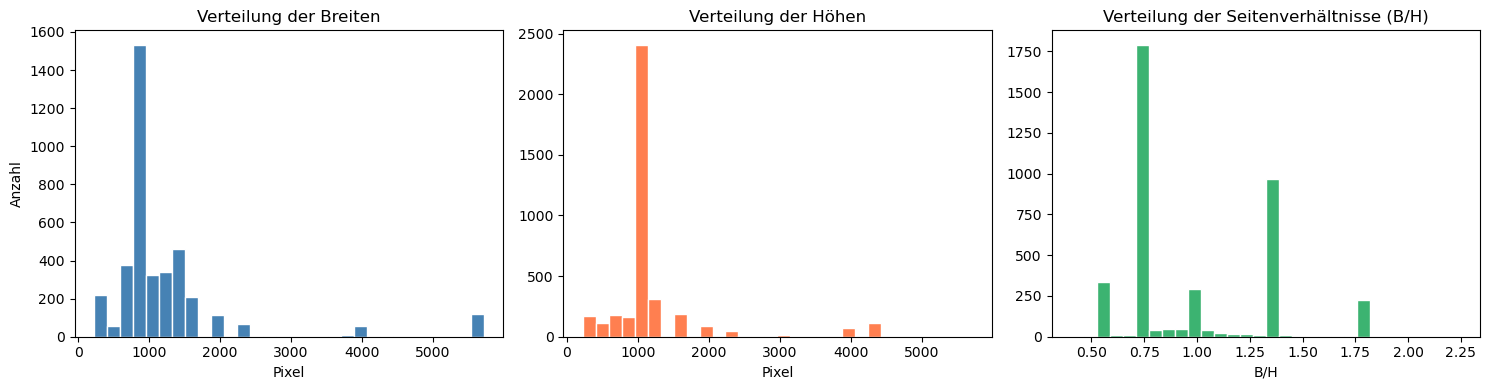

In [7]:
widths, heights, aspect_ratios, channels = [], [], [], []

for class_name in classes:
    class_path = Path(DATASET_PATH) / class_name
    for img_file in class_path.iterdir():
        if img_file.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp'}:
            with Image.open(img_file) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)
                aspect_ratios.append(w / h)
                channels.append(len(img.getbands()))

widths        = np.array(widths)
heights       = np.array(heights)
aspect_ratios = np.array(aspect_ratios)

print("=== Bildgrößen ===")
print(f"  Breite  – min: {widths.min()}, max: {widths.max()}, "
      f"Mittelwert: {widths.mean():.1f}, Std: {widths.std():.1f}")
print(f"  Höhe    – min: {heights.min()}, max: {heights.max()}, "
      f"Mittelwert: {heights.mean():.1f}, Std: {heights.std():.1f}")

print("\n=== Seitenverhältnisse (B/H) ===")
print(f"  min: {aspect_ratios.min():.3f}, max: {aspect_ratios.max():.3f}, "
      f"Mittelwert: {aspect_ratios.mean():.3f}, Std: {aspect_ratios.std():.3f}")

print("\n=== Farbkanäle ===")
channel_counts = Counter(channels)
for ch, cnt in sorted(channel_counts.items()):
    label = {1: "Graustufen", 3: "RGB", 4: "RGBA"}.get(ch, f"{ch} Kanäle")
    print(f"  {label}: {cnt} Bilder")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(widths,        bins=30, color='steelblue',     edgecolor='white')
axes[0].set_title('Verteilung der Breiten')
axes[0].set_xlabel('Pixel'); axes[0].set_ylabel('Anzahl')

axes[1].hist(heights,       bins=30, color='coral',         edgecolor='white')
axes[1].set_title('Verteilung der Höhen')
axes[1].set_xlabel('Pixel')

axes[2].hist(aspect_ratios, bins=30, color='mediumseagreen', edgecolor='white')
axes[2].set_title('Verteilung der Seitenverhältnisse (B/H)')
axes[2].set_xlabel('B/H')

plt.tight_layout()
plt.savefig('results/image_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Identification des défis potentiels du dataset

=== Klassenverteilung ===
  long-sleeved        : 787 Bilder
  pants               : 783 Bilder
  shorts              : 767 Bilder
  socks               : 781 Bilder
  t-shirt             : 781 Bilder

Ungleichgewichts-Verhältnis (max/min): 1.026
  ✅  Klassen gut ausbalanciert.

=== Weitere zu beachtende Punkte ===
  • Zielauflösung 224×224 (Originale: 224–5712px in der Breite).
  • Seitenverhältnisse B/H: 0.40–2.25 → direkte Größenänderung könnte die Bilder verzerren.


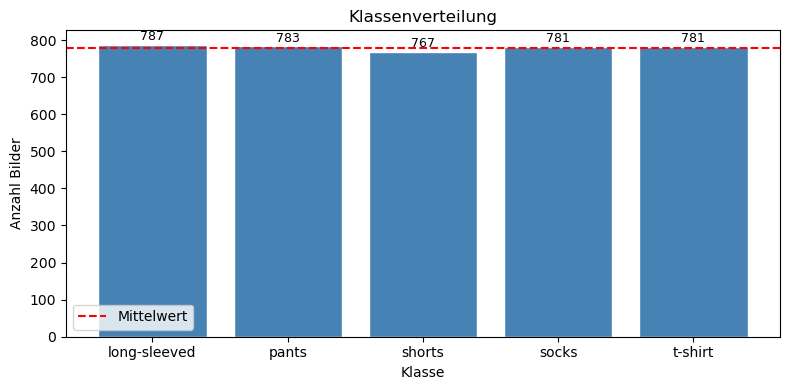

In [4]:
# Den rohen Datensatz temporär laden, um auf die Labels zuzugreifen
_raw_ds = datasets.ImageFolder(root=DATASET_PATH)
all_labels   = [label for _, label in _raw_ds]
label_counts = Counter(all_labels)
class_names  = _raw_ds.classes

print("=== Klassenverteilung ===")
counts = []
for idx, name in enumerate(class_names):
    n = label_counts[idx]
    counts.append(n)
    print(f"  {name:20s}: {n} Bilder")

total = sum(counts)
imbalance_ratio = max(counts) / min(counts)
print(f"\nUngleichgewichts-Verhältnis (max/min): {imbalance_ratio:.3f}")
if imbalance_ratio > 1.5:
    print("  ⚠️  Deutliches Ungleichgewicht – WeightedRandomSampler wird empfohlen.")
else:
    print("  ✅  Klassen gut ausbalanciert.")

# Weitere Hinweise
print("\n=== Weitere zu beachtende Punkte ===")
print(f"  • Zielauflösung 224×224 (Originale: "
      f"{widths.min()}–{widths.max()}px in der Breite).")
print(f"  • Seitenverhältnisse B/H: {aspect_ratios.min():.2f}–{aspect_ratios.max():.2f} "
      "→ direkte Größenänderung könnte die Bilder verzerren.")
if 1 in channel_counts:
    print(f"  • {channel_counts[1]} Bild(er) in Graustufen → "
          ".convert('RGB') im Transform hinzufügen.")
if 4 in channel_counts:
    print(f"  • {channel_counts[4]} Bild(er) RGBA → "
          "Alpha-Kanal muss entfernt werden.")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(class_names, counts, color='steelblue', edgecolor='white')
ax.axhline(total / len(class_names), color='red', linestyle='--', label='Mittelwert')
ax.set_title('Klassenverteilung')
ax.set_xlabel('Klasse'); ax.set_ylabel('Anzahl Bilder')
ax.legend()
for bar, cnt in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            str(cnt), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('results/class_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Konfiguration der Transforms und Augmentierungen

In [2]:
# ── Augmentierung nur für das Training ────────────────────────────────────────
train_transform = transforms.Compose([

    transforms.Resize(256),

    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ── Deterministische Transforms für Validierung und Test ─────────────────────
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),   # zentrierter Zuschnitt, reproduzierbar
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229,  0.224, 0.225])
])

print("Train-Transform :", train_transform)
print("\nEval-Transform  :", eval_transform)

Train-Transform : Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Eval-Transform  : Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 6. Dataset-Laden mit ImageFolder

In [8]:
# Zwei Versionen des Datensatzes: eine mit Augmentierung, eine ohne
full_train_ds = datasets.ImageFolder(root=DATASET_PATH, transform=train_transform)
full_eval_ds  = datasets.ImageFolder(root=DATASET_PATH, transform=eval_transform)

class_names = full_train_ds.classes

# Überprüfung anhand eines Beispiels
image, label = full_eval_ds[0]
print(f"Beispielbild:")
print(f"  • Tensor-Form : {image.shape}")
print(f"  • Label       : {label} ({class_names[label]})")
print(f"  • Min / Max   : {image.min():.3f} / {image.max():.3f}")
print(f"  • Klassen     : {class_names}")

Beispielbild:
  • Tensor-Form : torch.Size([3, 224, 224])
  • Label       : 0 (long-sleeved)
  • Min / Max   : -2.032 / 2.431
  • Klassen     : ['long-sleeved', 'pants', 'shorts', 'socks', 't-shirt']


## 7. Datensatz-Split: 80 % Training, 10 % Validierung, 10 % Test

In [7]:
total_size = len(full_train_ds)
train_size = int(0.8 * total_size)
val_size   = int(0.1 * total_size)
test_size  = total_size - train_size - val_size

# Aufteilung anhand der Indizes, mit festem Seed für Reproduzierbarkeit
_base = datasets.ImageFolder(root=DATASET_PATH)  # ohne Transform, nur zum Aufteilen
_, _, _ = random_split(
    _base, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)
split = random_split(
    _base, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)
train_indices = split[0].indices
val_indices   = split[1].indices
test_indices  = split[2].indices

# Die passenden Transforms auf jedes Teildataset anwenden
train_ds = Subset(full_train_ds, train_indices)  # mit Augmentierung
val_ds   = Subset(full_eval_ds,  val_indices)    # ohne Augmentierung
test_ds  = Subset(full_eval_ds,  test_indices)   # ohne Augmentierung

print(f"Gesamtgröße  : {total_size}")
print(f"  Train      : {len(train_ds)} Bilder ({len(train_ds)/total_size*100:.0f}%)")
print(f"  Validation : {len(val_ds)}  Bilder ({len(val_ds)/total_size*100:.0f}%)")
print(f"  Test       : {len(test_ds)}  Bilder ({len(test_ds)/total_size*100:.0f}%)")

Gesamtgröße  : 3899
  Train      : 3119 Bilder (80%)
  Validation : 389  Bilder (10%)
  Test       : 391  Bilder (10%)


## 8. Erstellung des DataLoaders

In [8]:
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pin_memory = device.type == "cuda"

print(f"genutzt Device : {device}")
print(f"pin_memory     : {pin_memory}")

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,
                          num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False,
                          num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False,
                          num_workers=0, pin_memory=True)

print(f"Train      : {len(train_ds)} Bilder → {len(train_loader)} Batches")
print(f"Validation : {len(val_ds)}  Bilder → {len(val_loader)}  Batches")
print(f"Test       : {len(test_ds)}  Bilder → {len(test_loader)}  Batches")

genutzt Device : cpu
pin_memory     : False
Train      : 3119 Bilder → 98 Batches
Validation : 389  Bilder → 13  Batches
Test       : 391  Bilder → 13  Batches


## 9. Darstellung der augmentierten Bilder

C:\Users\Lenovo\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


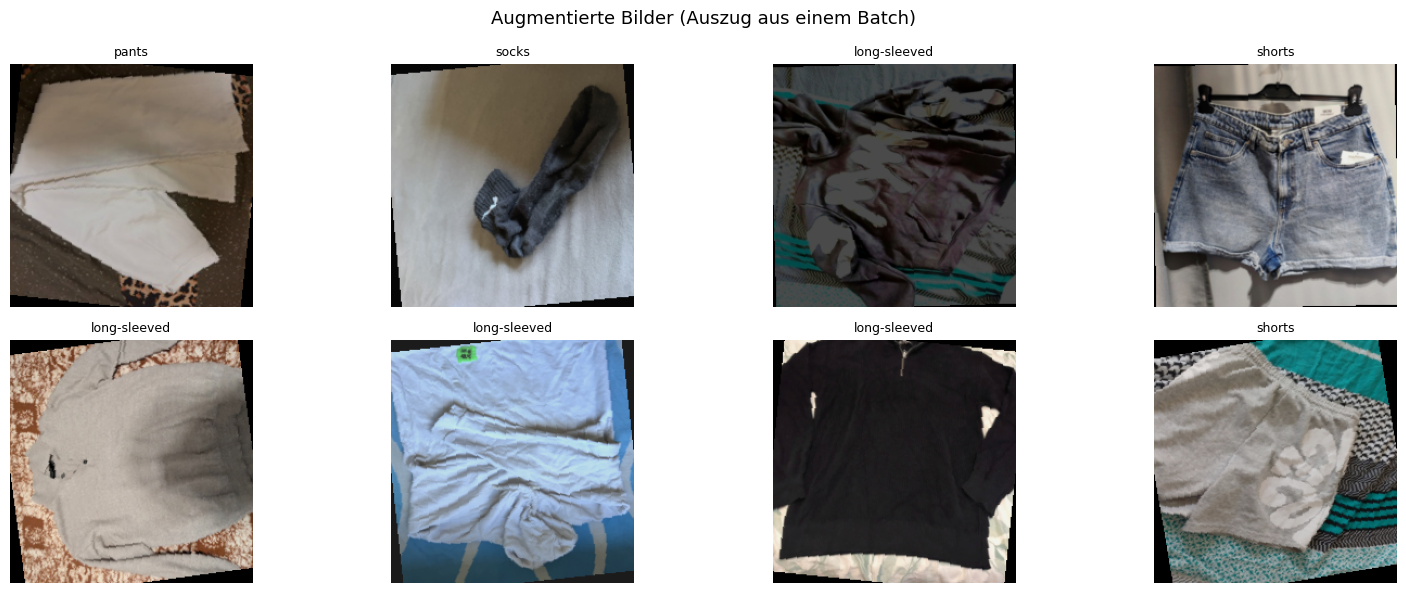

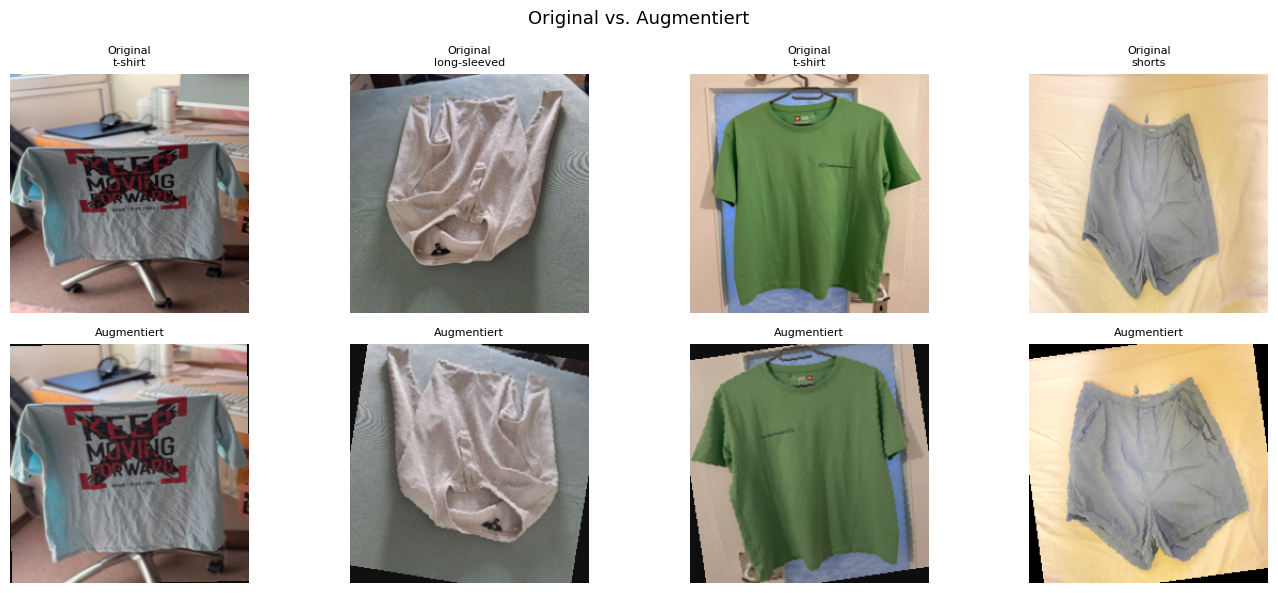

In [9]:
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229,  0.224, 0.225]).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)

# ── 8 Bilder aus einem Trainings-Batch ────────────────────────────────────────
images, labels = next(iter(train_loader))
n_show = 8

fig, axes = plt.subplots(2, n_show // 2, figsize=(16, 6))
axes = axes.flatten()
for i in range(n_show):
    img = denormalize(images[i]).permute(1, 2, 0).numpy()
    axes[i].imshow(img)
    axes[i].set_title(class_names[labels[i].item()], fontsize=9)
    axes[i].axis('off')
fig.suptitle('Augmentierte Bilder (Auszug aus einem Batch)', fontsize=13)
plt.tight_layout()
plt.savefig('results/augmented_samples.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Vergleich Original vs. Augmentiert ────────────────────────────────────────
raw_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

sample_indices = [train_indices[i * 80] for i in range(4)]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))

for col, idx in enumerate(sample_indices):
    img_path, lbl = full_train_ds.imgs[idx]

    raw_img = raw_transform(Image.open(img_path).convert('RGB'))
    axes[0, col].imshow(raw_img.permute(1, 2, 0).numpy())
    axes[0, col].set_title(f'Original\n{class_names[lbl]}', fontsize=8)
    axes[0, col].axis('off')

    aug_img, _ = full_train_ds[idx]
    axes[1, col].imshow(denormalize(aug_img).permute(1, 2, 0).numpy())
    axes[1, col].set_title('Augmentiert', fontsize=8)
    axes[1, col].axis('off')

axes[0, 0].set_ylabel('Original',   fontsize=10)
axes[1, 0].set_ylabel('Augmentiert',   fontsize=10)
fig.suptitle('Original vs. Augmentiert', fontsize=13)
plt.tight_layout()
plt.savefig('results/original_vs_augmented.png', dpi=120, bbox_inches='tight')
plt.show()

## 10. CNN Architektur

In [3]:
import torch.nn as nn
import torch.nn.functional as F

class ClothingCNN(nn.Module):
    def __init__(self, num_classes=5, dropout1=0.3, dropout2=0.2):
        super().__init__()

        # ── Blocs de convolution ──────
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        # Ajout de la couche GAP (la correction pour ton erreur)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        # Classifieur
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout1),
            nn.Linear(256, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout2),
            nn.Linear(256, num_classes)
        )

## 11. Erstellung und Überprüfung des Modells

In [10]:
# ── Définition du Forward Pass ──────────────────────────────────────────────
def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    x = self.block4(x)
    x = self.gap(x)
    x = torch.flatten(x, 1) # Aplatir ici
    x = self.classifier(x)
    return x

# Injecter la méthode forward dans la classe
ClothingCNN.forward = forward

# Instanciation et Test
model = ClothingCNN(num_classes=5)
dummy = torch.zeros(4, 3, 224, 224)
with torch.no_grad():
    out = model(dummy)
print(f"Forward-Pass OK : Entrée {list(dummy.shape)} → Sortie {list(out.shape)}")

Forward-Pass OK : Entrée [4, 3, 224, 224] → Sortie [4, 5]


## 12. Verlustfunktion und Optimierer

In [12]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

# ── Modell auf das richtige Device verschieben ──────────────────────────────
model = model.to(device)

# ── Verlustfunktion ──────────────────────────────────────────────────────────
# CrossEntropyLoss: Standard für Multi-Klassen-Klassifikation.
# Kombiniert LogSoftmax + NLLLoss in einer einzigen numerisch stabilen Operation.
# Die Klassen sind ausgewogen (~780 Bilder pro Klasse) → keine Gewichtung nötig.
criterion = nn.CrossEntropyLoss()

# ── Optimierer ────────────────────────────────────────────────────────────────
# Adam: adaptiv, konvergiert schnell, robust gegenüber der Wahl der initialen lr.
# lr=1e-3 ist der klassische Ausgangspunkt für Adam auf CNNs mittlerer Größe.
# weight_decay=1e-4: leichte L2-Regularisierung, bestraft große Gewichte
#                     und ergänzt Dropout zur Begrenzung von Overfitting.
optimizer = optim.Adam(model.parameters(), lr=3e-4, weight_decay=1e-4) 
#lr=5e-4

# ── Scheduler: reduziert die lr, wenn die val_loss stagniert ────────────────
# factor=0.5: teilt die lr bei jedem Plateau durch 2
# patience=3: wartet 3 Epochen ohne Verbesserung, bevor reduziert wird
# min_lr=1e-6: Untergrenze, um eine zu kleine lr zu vermeiden
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5,
                               patience=3, min_lr=1e-6)

print(f"Modell auf : {device}")
print(f"Verlustfunktion : {criterion}")
print(f"Optimierer : {optimizer.__class__.__name__}  (lr={optimizer.param_groups[0]['lr']}, "
      f"weight_decay={optimizer.param_groups[0]['weight_decay']})")
print(f"Scheduler  : ReduceLROnPlateau (factor=0.5, patience=3)")

Modell auf : cpu
Verlustfunktion : CrossEntropyLoss()
Optimierer : Adam  (lr=0.0003, weight_decay=0.0001)
Scheduler  : ReduceLROnPlateau (factor=0.5, patience=3)


## 13. Early Stopping

In [13]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=1e-4, path='best_model.pth'):
        self.patience   = patience
        self.min_delta  = min_delta
        self.path       = path
        self.best_loss  = float('inf')
        self.counter    = 0
        self.best_epoch = 0
        self.stop       = False

    def __call__(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            # Verbesserung → Modell speichern und Zähler zurücksetzen
            self.best_loss  = val_loss
            self.best_epoch = epoch
            self.counter    = 0
            torch.save(model.state_dict(), self.path)
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

    def load_best(self, model):
        model.load_state_dict(torch.load(self.path, map_location=device))
        return model

early_stopping = EarlyStopping(patience=7, min_delta=1e-4, path='best_model.pth')
print("EarlyStopping konfiguriert : patience=7, min_delta=1e-4")

EarlyStopping konfiguriert : patience=7, min_delta=1e-4


## 14. Training des Modells

In [14]:
import wandb


# W&B Konfiguration
try:
    wandb.login()  # liest den API-Key aus der Umgebungsvariable WANDB_API_KEY
except Exception as e:
    print(f"Fehler: {e}")
WANDB_ENTITY = "eidl-thm"
WANDB_PROJECT = "abgabe2"

run = wandb.init(
    entity=WANDB_ENTITY,
    project=WANDB_PROJECT,
    name="Uebungsgruppe_Vades_Ngounouo_Lister_Melaguie_runtime2",
    config={
        "architecture": "ClothingCNN",
        "dataset_path": DATASET_PATH,
        "image_size": 224,
        "batch_size": 32,
        "optimizer": optimizer.__class__.__name__,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "weight_decay": optimizer.param_groups[0]["weight_decay"],
        "scheduler": "ReduceLROnPlateau",
        "early_stopping_patience": early_stopping.patience,
        "num_epochs": 100
    },
    job_type="train"
 )

# Log gradients/weights während des Trainings
wandb.watch(model, criterion=criterion, log="all", log_freq=50)
print(f"W&B Run gestartet: {run.name} ({run.id})")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\Lenovo\_netrc
wandb: Currently logged in as: vadesdjoko (eidl-thm) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B Run gestartet: Uebungsgruppe_Vades_Ngounouo_Lister_Melaguie_runtime2 (dze3vnis)


## 14.b Weights & Biases (W&B) Initialisierung

In [15]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds       = outputs.argmax(dim=1)
        correct    += (preds == labels).sum().item()
        total      += images.size(0)

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss    = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            preds       = outputs.argmax(dim=1)
            correct    += (preds == labels).sum().item()
            total      += images.size(0)

    return total_loss / total, correct / total


# ── Verlauf ───────────────────────────────────────────────────────────────────
history = {'train_loss': [], 'val_loss': [],
           'train_acc':  [], 'val_acc':  []}

NUM_EPOCHS = 50

print(f"{'Epoche':>6} | {'Train Loss':>10} | {'Train Acc':>9} | "
      f"{'Val Loss':>9} | {'Val Acc':>8} | {'Aktuelle LR':>10}")
print("─" * 70)

for epoch in range(1, NUM_EPOCHS + 1):

    train_loss, train_acc = train_one_epoch(model, train_loader,
                                            criterion, optimizer, device)
    val_loss,   val_acc   = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)
    early_stopping(val_loss, model, epoch)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    lr_now = optimizer.param_groups[0]['lr']
    marker = " ← best" if early_stopping.counter == 0 else ""
    print(f"{epoch:>6} | {train_loss:>10.4f} | {train_acc:>8.2%} | "
          f"{val_loss:>9.4f} | {val_acc:>7.2%} | {lr_now:>10.2e}{marker}")

    if wandb.run is not None:
        wandb.log({
            "epoch": epoch,
            "train/loss": train_loss,
            "train/accuracy": train_acc,
            "val/loss": val_loss,
            "val/accuracy": val_acc,
            "train/lr": lr_now,
            "val/is_best_epoch": int(early_stopping.counter == 0)
        })

    if early_stopping.stop:
        print(f"\n⛔  Early Stopping bei Epoche {epoch}. "
              f"Bestes Modell: Epoche {early_stopping.best_epoch} "
              f"(val_loss={early_stopping.best_loss:.4f})")
        break

# Bestes Modell neu laden
model = early_stopping.load_best(model)
print(f"\n✅  Bestes Modell aus Epoche {early_stopping.best_epoch} neu geladen.")

if wandb.run is not None:
    wandb.summary["best_epoch"] = early_stopping.best_epoch
    wandb.summary["best_val_loss"] = early_stopping.best_loss

Epoche | Train Loss | Train Acc |  Val Loss |  Val Acc | Aktuelle LR
──────────────────────────────────────────────────────────────────────


C:\Users\Lenovo\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


     1 |     1.5976 |   25.39% |    1.5870 |  24.94% |   3.00e-04 ← best
     2 |     1.5637 |   28.37% |    1.5524 |  30.59% |   3.00e-04 ← best
     3 |     1.5458 |   29.46% |    1.5198 |  31.62% |   3.00e-04 ← best
     4 |     1.5198 |   32.22% |    1.4765 |  34.96% |   3.00e-04 ← best
     5 |     1.5108 |   33.47% |    1.4810 |  32.90% |   3.00e-04
     6 |     1.4942 |   34.37% |    1.4607 |  36.25% |   3.00e-04 ← best
     7 |     1.4840 |   35.59% |    1.4743 |  33.93% |   3.00e-04
     8 |     1.4670 |   36.04% |    1.4228 |  39.59% |   3.00e-04 ← best
     9 |     1.4495 |   37.32% |    1.4091 |  42.93% |   3.00e-04 ← best
    10 |     1.4209 |   38.15% |    1.4070 |  40.87% |   3.00e-04 ← best
    11 |     1.4095 |   40.30% |    1.3745 |  39.07% |   3.00e-04 ← best
    12 |     1.4001 |   40.40% |    1.4633 |  36.76% |   3.00e-04
    13 |     1.3918 |   40.78% |    1.3619 |  42.42% |   3.00e-04 ← best
    14 |     1.3649 |   42.13% |    1.5049 |  40.36% |   3.00e-04
    15

## 15. Lernkurven

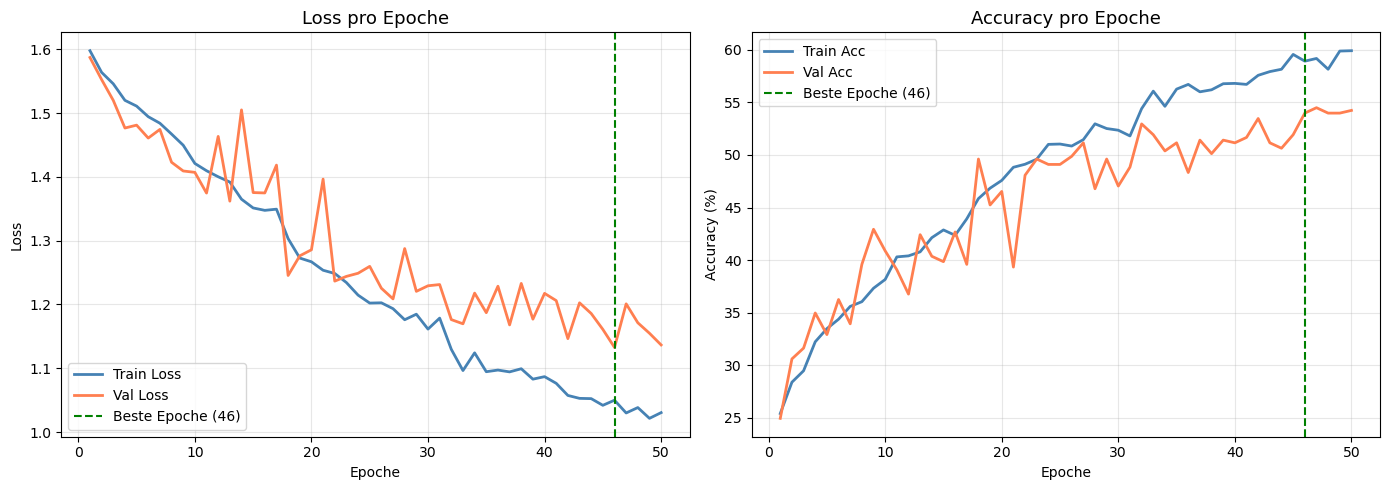

Plot gespeichert : training_curves.png


In [16]:
epochs_ran = range(1, len(history['train_loss']) + 1)
best_ep    = early_stopping.best_epoch

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ── Loss ──────────────────────────────────────────────────────────────────────
ax1.plot(epochs_ran, history['train_loss'], label='Train Loss',
         color='steelblue', linewidth=2)
ax1.plot(epochs_ran, history['val_loss'],   label='Val Loss',
         color='coral',     linewidth=2)
ax1.axvline(best_ep, color='green', linestyle='--', linewidth=1.5,
            label=f'Beste Epoche ({best_ep})')
ax1.set_title('Loss pro Epoche', fontsize=13)
ax1.set_xlabel('Epoche'); ax1.set_ylabel('Loss')
ax1.legend(); ax1.grid(alpha=0.3)

# ── Accuracy ──────────────────────────────────────────────────────────────────
ax2.plot(epochs_ran, [a*100 for a in history['train_acc']],
         label='Train Acc', color='steelblue', linewidth=2)
ax2.plot(epochs_ran, [a*100 for a in history['val_acc']],
         label='Val Acc',   color='coral',     linewidth=2)
ax2.axvline(best_ep, color='green', linestyle='--', linewidth=1.5,
            label=f'Beste Epoche ({best_ep})')
ax2.set_title('Accuracy pro Epoche', fontsize=13)
ax2.set_xlabel('Epoche'); ax2.set_ylabel('Accuracy (%)')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('results/training_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print("Plot gespeichert : training_curves.png")

## 16. Bewertung auf dem Testdatensatz

C:\Users\Lenovo\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Gesamtgenauigkeit auf dem Testset : 53.71%

Klassifikationsbericht :
              precision    recall  f1-score   support

long-sleeved      0.510     0.298     0.376        84
       pants      0.559     0.747     0.639        83
      shorts      0.373     0.322     0.345        59
       socks      0.654     0.726     0.688        73
     t-shirt      0.515     0.554     0.534        92

    accuracy                          0.537       391
   macro avg      0.522     0.529     0.517       391
weighted avg      0.528     0.537     0.523       391



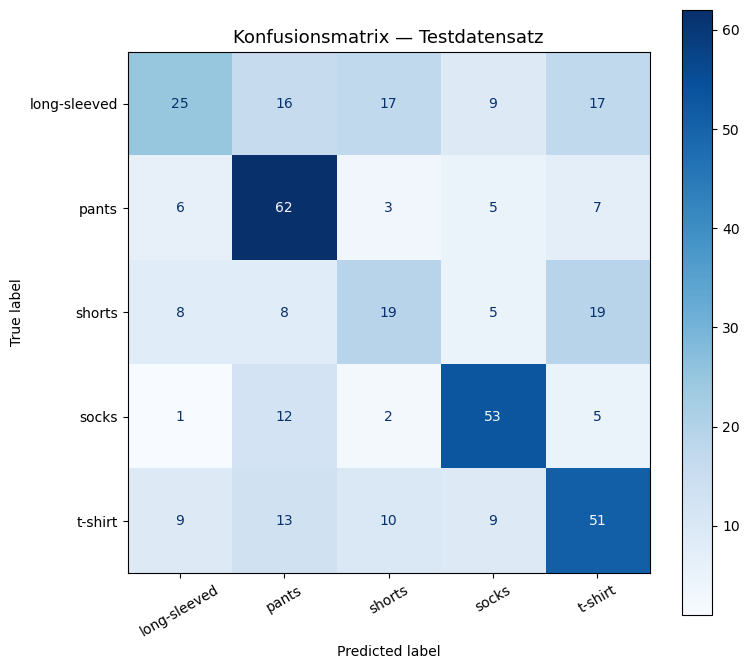

Plot gespeichert : confusion_matrix.png


In [17]:
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay)

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds   = outputs.argmax(dim=1).cpu()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.tolist())

all_preds  = torch.tensor(all_preds)
all_labels = torch.tensor(all_labels)

# ── Gesamtgenauigkeit ──────────────────────────────────────────────────────────
overall_acc = (all_preds == all_labels).float().mean().item()
print(f"Gesamtgenauigkeit auf dem Testset : {overall_acc:.2%}\n")

# ── Bericht pro Klasse ────────────────────────────────────────────────────────
report_dict = classification_report(
    all_labels, all_preds, target_names=class_names, digits=3, output_dict=True
 )
print("Klassifikationsbericht :")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

# ── Konfusionsmatrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, colorbar=True, cmap='Blues', xticks_rotation=30)
ax.set_title('Konfusionsmatrix — Testdatensatz', fontsize=13)
plt.tight_layout()
plt.savefig('results/confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()
print("Plot gespeichert : confusion_matrix.png")

if wandb.run is not None:
    # Metriken im Run-Summary sichern
    wandb.summary["test/accuracy"] = overall_acc
    wandb.log({"test/confusion_matrix": wandb.Image("results/confusion_matrix.png")})

    # Pro-Klasse Metriken loggen (precision/recall/f1)
    class_rows = []
    for class_name in class_names:
        class_rows.append([
            class_name,
            report_dict[class_name]["precision"],
            report_dict[class_name]["recall"],
            report_dict[class_name]["f1-score"],
            report_dict[class_name]["support"]
        ])

    wandb.log({
        "test/classification_report": wandb.Table(
            columns=["class", "precision", "recall", "f1", "support"],
            data=class_rows
        )
    })

## 17. Analyse der falsch klassifizierten Bilder

C:\Users\Lenovo\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


14 falsch klassifizierte Bilder gefunden — 12 werden angezeigt.


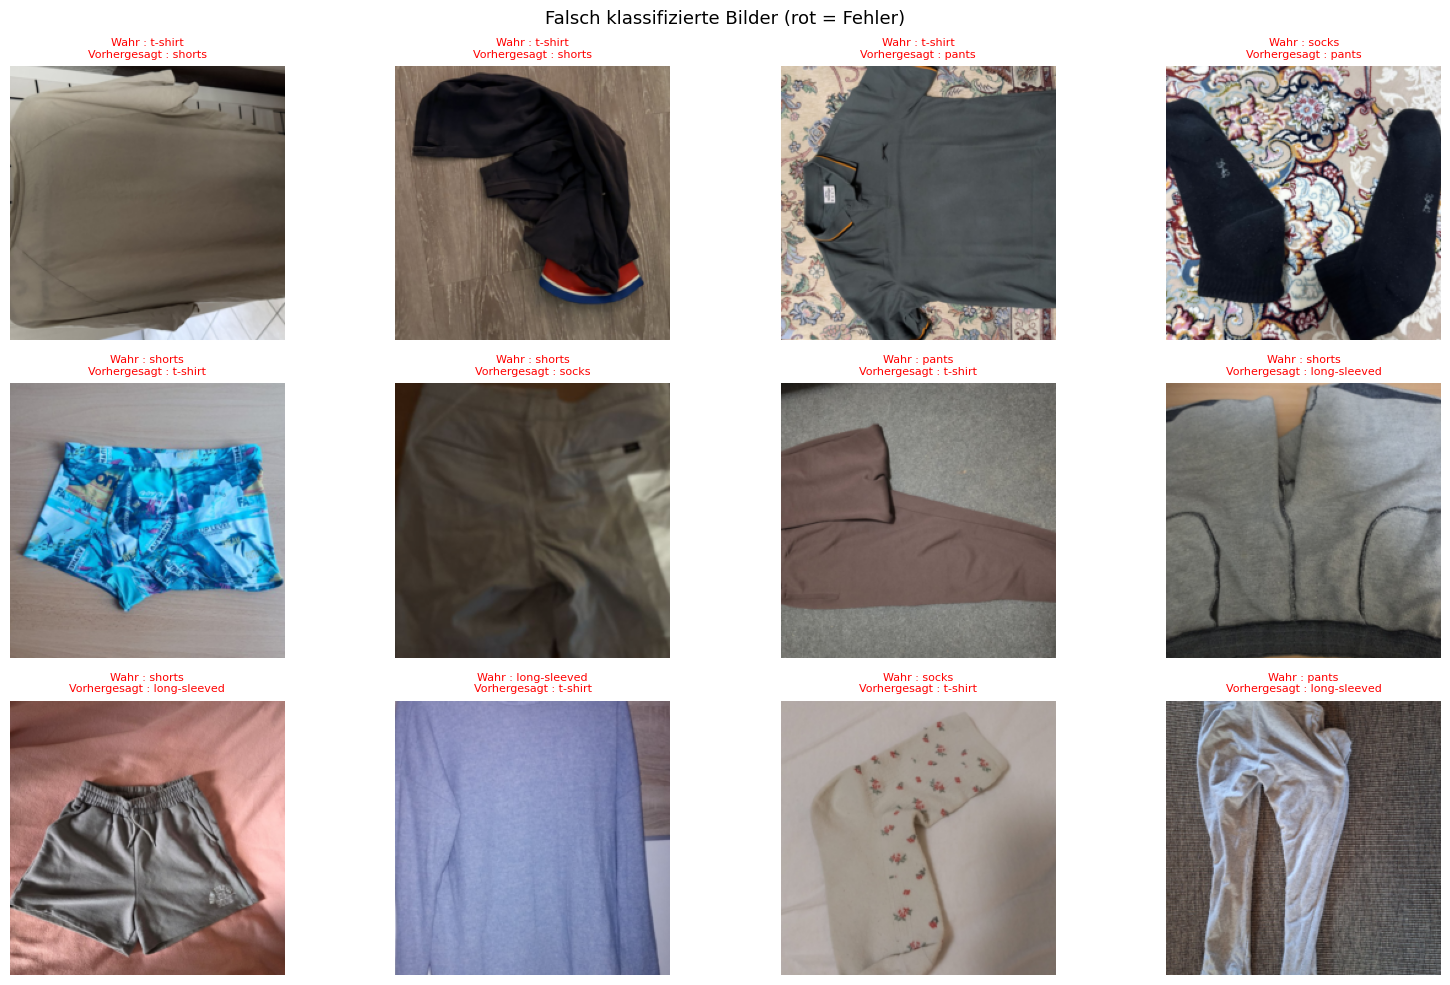


Häufigste Verwechslungspaare (wahr → vorhergesagt) :
  t-shirt              → shorts               : 2 mal
  t-shirt              → pants                : 2 mal
  shorts               → t-shirt              : 2 mal
  shorts               → long-sleeved         : 2 mal
  socks                → pants                : 1 mal
  shorts               → socks                : 1 mal
  pants                → t-shirt              : 1 mal
  long-sleeved         → t-shirt              : 1 mal


In [18]:
# Die falsch klassifizierten Bilder mit ihren Vorhersagen sammeln
model.eval()
misclassified = []   # (image_tensor, true_label, pred_label)

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        preds   = outputs.argmax(dim=1).cpu()
        wrong   = preds != labels
        for img, true, pred in zip(images[wrong], labels[wrong], preds[wrong]):
            misclassified.append((img, true.item(), pred.item()))
        if len(misclassified) >= 12:
            break

n_show = min(12, len(misclassified))
print(f"{len(misclassified)} falsch klassifizierte Bilder gefunden — {n_show} werden angezeigt.")

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i in range(n_show):
    img, true_lbl, pred_lbl = misclassified[i]
    img_display = denormalize(img).permute(1, 2, 0).numpy()
    axes[i].imshow(img_display)
    axes[i].set_title(
        f"Wahr : {class_names[true_lbl]}\nVorhergesagt : {class_names[pred_lbl]}",
        fontsize=8,
        color='red' if true_lbl != pred_lbl else 'green'
    )
    axes[i].axis('off')

for j in range(n_show, len(axes)):
    axes[j].axis('off')

fig.suptitle('Falsch klassifizierte Bilder (rot = Fehler)', fontsize=13)
plt.tight_layout()
plt.savefig('results/misclassified.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Analyse der häufigsten Verwechslungen ────────────────────────────────────
print("\nHäufigste Verwechslungspaare (wahr → vorhergesagt) :")
confusion_pairs = {}
for _, true, pred in misclassified:
    key = (class_names[true], class_names[pred])
    confusion_pairs[key] = confusion_pairs.get(key, 0) + 1

for (true_name, pred_name), count in sorted(confusion_pairs.items(),
                                             key=lambda x: -x[1])[:8]:
    print(f"  {true_name:20s} → {pred_name:20s} : {count} mal")


# Mögliche Ursachen für Klassifikationsfehler

* **Visuelle Ähnlichkeit:** Shorts und Hosen teilen die gleiche Grundform (zwei Beine) und können je nach Bildausschnitt verwechselt werden.
* **Innerklassische Varianz:** Ein sehr lang getragenes T-Shirt kann je nach Perspektive einem Kleid oder einem Langarmshirt ähneln.
* **Bildausschnittqualität:** Wenn das Kleidungsstück nicht zentriert oder nur teilweise sichtbar ist, gehen unterscheidende Merkmale (Kragen, Länge) verloren.
* **Augmentierung:** Eine zu aggressive Rotation oder ein zu starker Zuschnitt kann das charakteristische Element verdecken (z. B. Socken abgeschnitten = neutraler Stoff).
* **Effektive Auflösung:** Nach 4 MaxPool-Layern ist die Karte 14×14 — feine Details (Nähte, Texturen) gehen verloren, was ähnliche Klassen wie Socken vs. T-Shirt (kleine Fläche, wenig Kontext) benachteiligt.

In [19]:
# ── W&B Artefakte hochladen und Run sauber beenden ────────────────────────────
if wandb.run is not None:
    artifact = wandb.Artifact(
        name="clothingcnn-best-model",
        type="model",
        description="Bestes Modell CNN (EarlyStopping)",
        metadata={
            "best_epoch": early_stopping.best_epoch,
            "best_val_loss": float(early_stopping.best_loss),
            "num_classes": len(class_names),
            "classes": class_names
        }
    )

    artifact.add_file("best_model.pth")

    for file_name in [
        "results/training_curves.png",
        "results/confusion_matrix.png",
        "results/class_distribution.png",
        "results/image_distribution.png",
        "results/augmented_samples.png",
        "results/original_vs_augmented.png",
        "results/misclassified.png"
    ]:
        if os.path.exists(file_name):
            artifact.add_file(file_name)

    wandb.log_artifact(artifact)
    wandb.finish()
    print("W&B: artefacts uploadés et run terminé.")
else:
    print("Aucun run W&B actif. Lance d'abord la cellule d'initialisation W&B.")

epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇██
train/accuracy,▁▂▂▂▃▃▃▃▄▄▄▄▅▄▅▅▅▆▆▆▆▆▆▇▆▆▇▇▇▇▇▇▇▇██████
train/loss,██▇▇▇▇▆▆▆▆▅▅▅▅▅▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁
train/lr,████████████▄▄▄▄▄▄▄▄▄▄▄▄▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
val/accuracy,▁▂▃▃▃▄▅▅▄▄▅▅▅▄▇▆▄▆▇▇▇▇▆▇▆▇▇▇▇▇▇▇▇█▇▇████
val/is_best_epoch,████▁▁███▁▁▁▁▁█▁▁█▁▁██▁▁▁██▁▁▁▁▁▁▁█▁▁█▁▁
val/loss,█▇▇▆▆▆▅▅▅▅▇▅▅▅▃▃▅▃▃▃▂▃▂▂▃▂▂▂▂▂▂▂▂▁▂▁▁▂▂▁
best_epoch,46
best_val_loss,1.13259
epoch,50
test/accuracy,0.53708


W&B: artefacts uploadés et run terminé.


## Klassifikation der Testdaten aus EiDL_TestDaten_SoSe26_res

In [16]:
import os
import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
from PIL import Image
from torchvision import transforms

# ── 1. Paramètres ──────────────────────────────────────────────────────────────
TEST_DIR   = './EiDL_TestDaten_SoSe26'
MODEL_PATH = 'best_model.pth'
DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── 2. class_names ─────────────────────────────────────────────────────────────
DATASET_PATH = './dataset'
class_names  = sorted([
    d for d in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, d))
])
print("Klassen :", class_names)

# ── 3. Architektur ─────────────────────────────────────────────────────────────
class ClothingCNN(nn.Module):
    def __init__(self, num_classes=5, dropout1=0.3, dropout2=0.2):
        super().__init__()
        self.block1 = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.block2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.block3 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.block4 = nn.Sequential(nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(nn.Dropout(p=dropout1), nn.Linear(256, 256), nn.ReLU(inplace=True), nn.Dropout(p=dropout2), nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.block1(x); x = self.block2(x); x = self.block3(x); x = self.block4(x)
        x = self.gap(x); x = torch.flatten(x, 1); x = self.classifier(x)
        return x

# ── 4. Modell laden ────────────────────────────────────────────────────────────
model = ClothingCNN(num_classes=len(class_names))
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.to(DEVICE)
model.eval()
print("Modell geladen ✅")

# ── 5. Transform ───────────────────────────────────────────────────────────────
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ── 6. Klassifikation ──────────────────────────────────────────────────────────
SUPPORTED_EXTS = {'.png', '.jpg', '.jpeg', '.bmp'}
test_files = sorted([p for p in Path(TEST_DIR).rglob('*') if p.suffix.lower() in SUPPORTED_EXTS])
print(f"Gefundene Bilder : {len(test_files)}")

results = []
with torch.no_grad():
    for img_path in test_files:
        img      = Image.open(img_path).convert('RGB')
        tensor   = eval_transform(img).unsqueeze(0).to(DEVICE)
        probs    = torch.softmax(model(tensor), dim=1)[0]
        pred_idx = probs.argmax().item()
        results.append({
            'Dateiname'     : img_path.name,
            'Wahre Klasse'  : img_path.parent.name,
            'Pred Klasse'   : class_names[pred_idx],
            'Korrekt'       : '✅' if img_path.parent.name == class_names[pred_idx] else '❌',
            'Konfidenz (%)'  : f'{probs[pred_idx].item()*100:.2f}'
        })

df = pd.DataFrame(results)
print(df.to_string(index=False))

# ── 7. Gesamtgenauigkeit ───────────────────────────────────────────────────────
correct = (df['Wahre Klasse'] == df['Pred Klasse']).sum()
print(f"\nGenauigkeit : {correct}/{len(df)} = {correct/len(df)*100:.2f}%")

df.to_csv('results/testdaten_klassifikation.csv', index=False)
print("Gespeichert → testdaten_klassifikation.csv")

Klassen : ['long-sleeved', 'pants', 'shorts', 'socks', 't-shirt']
Modell geladen ✅
Gefundene Bilder : 99
         Dateiname Wahre Klasse  Pred Klasse Korrekt Konfidenz (%)
long-sleeved01.jpg long-sleeved      t-shirt       ❌         60.45
long-sleeved02.jpg long-sleeved      t-shirt       ❌         58.47
long-sleeved03.jpg long-sleeved      t-shirt       ❌         72.27
long-sleeved04.jpg long-sleeved long-sleeved       ✅         38.60
long-sleeved05.jpg long-sleeved       shorts       ❌         39.44
long-sleeved06.jpg long-sleeved        pants       ❌         53.84
long-sleeved07.jpg long-sleeved long-sleeved       ✅         58.04
long-sleeved08.jpg long-sleeved long-sleeved       ✅         32.01
long-sleeved09.jpg long-sleeved       shorts       ❌         30.17
long-sleeved10.jpg long-sleeved      t-shirt       ❌         71.88
long-sleeved11.jpg long-sleeved      t-shirt       ❌         42.55
long-sleeved12.jpg long-sleeved long-sleeved       ✅         69.43
long-sleeved13.jpg long-